
## EE 502 P: Analytical Methods for Electrical Engineering
    
# Homework 7: Graphs and Networks
## Due December 4, 2022 by 11:59 PM
### <span style="color: red">YOUR NAME HERE</span>

Copyright &copy; 2022, University of Washington

<hr>

**Instructions**: Please use this notebook as a template. Answer all questions using well formatted Markdown with embedded LaTeX equations, executable Jupyter cells, or both. Submit your homework solutions as an `.ipynb` file via Canvas.

<span style="color: red'">
Although you may discuss the homework with others, you must turn in your own, original work.
</span>

**Things to remember:**
- Use complete sentences. Equations should appear in text as grammatical elements.
- Comment your code.
- Label your axes. Title your plots. Use legends where appropriate. 
- Before submitting a notebook, choose Kernel -> Restart and Run All to make sure your notebook runs when the cells are evaluated in order. 

### 0. Warmup (Do not turn in)

- Make sure you download, read, and run the notebook for lectures 8 and 9. Work through the notebook cell by cell and see what happens when you change the expressions, and make up some of your own.
- The material covered in class is intended to be an introductory overview of the incredibly rich and expansive subject of Graph Theory.
- Most of the section on basic graph theory is from chapter one of

> Bollobas, [Modern Graph Theory](https://www.springer.com/gp/book/9780387984889).

- The spanning tree algorithm by Prim is from 

> Gibbons, [Algorithmic Graph Theory](https://www.amazon.com/Algorithmic-Graph-Theory-Alan-Gibbons/dp/0521288819). 

- Graphs as matrices is covered in 

> Nica, [A Brief Introduction to Spectral Graph Theory](https://www.amazon.com/Introduction-Spectral-Theory-Textbooks-Mathematics/dp/3037191880/ref=sr_1_2?crid=3ETRQ8B0PW4EJ&keywords=spectral+graph+theory&qid=1573687537&s=books&sprefix=spectral+graph%2Cstripbooks%2C195&sr=1-2).

The consensus algorithm is described in [these notes](http://www.eeci-institute.eu/pdf/M010/Eeci-sp09_L4_graphtheory.pdf) by Richard Murray.

You will also need `networkx` which can be obtained [here](https://networkx.github.io/). If you are on Google CoLab, see [here](https://stackoverflow.com/questions/51342408/how-do-i-install-python-packages-in-googles-colab) for how to install packages. 

- Most of the section on probability is from chapter of the really, really, really good book:

> Feller, [An Introduction to Probability Theory and Its Applications, Vol 1](https://www.amazon.com/Introduction-Probability-Theory-Applications-Vol/dp/0471257087), 3rd Edition, Wiley, 1968. 

- The material on Markov Chains can be found in numerous textbooks. A good online source is Chapter 11 of 

> Grinstead, [Introduction to Probability](http://www.dartmouth.edu/~chance/teaching_aids/books_articles/probability_book/book.html).

In [11]:
import networkx as nx
import numpy as np
import math as mt
import matplotlib.pyplot as plt

## 1. Creating a Graph

Let $V = \{ 1, ..., 20 \}$ and say that $uv \in E$ if and only if $u$ and $v$ have a common factor other than $1$. Use `networkx` to define this graph and render it. Make sure to label the nodes.

In [13]:
G = nx.Graph()
G.add_nodes_from(list(range(1, 21)))
G.add_edges_from([(i, j) for i in range(1, 21) for j in range(1, 21) if i != j and mt.gcd(i, j) != 1])

In [14]:
# verify
print("Nodes:")
print(G.nodes())
print("Edges:")
print(G.edges())

Nodes:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Edges:
[(2, 4), (2, 6), (2, 8), (2, 10), (2, 12), (2, 14), (2, 16), (2, 18), (2, 20), (3, 6), (3, 9), (3, 12), (3, 15), (3, 18), (4, 6), (4, 8), (4, 10), (4, 12), (4, 14), (4, 16), (4, 18), (4, 20), (5, 10), (5, 15), (5, 20), (6, 8), (6, 9), (6, 10), (6, 12), (6, 14), (6, 15), (6, 16), (6, 18), (6, 20), (7, 14), (8, 10), (8, 12), (8, 14), (8, 16), (8, 18), (8, 20), (9, 12), (9, 15), (9, 18), (10, 12), (10, 14), (10, 15), (10, 16), (10, 18), (10, 20), (12, 14), (12, 15), (12, 16), (12, 18), (12, 20), (14, 16), (14, 18), (14, 20), (15, 18), (15, 20), (16, 18), (16, 20), (18, 20)]


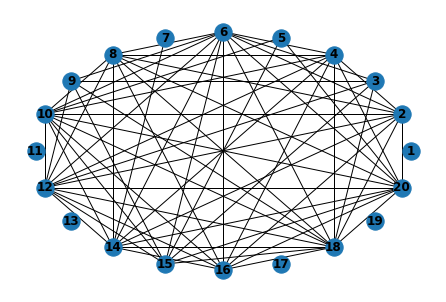

In [16]:
# render it
nx.draw_circular(G, with_labels=True, font_weight='bold')

## 2. Bipartite Graphs

a) What is the greatest number of edges a connected bipartite graph with $5$ nodes can have? Draw all five node graphs with this number of edges (up to isomorphism).

b) What is the least number of edges a connected bipartite graph with $5$ nodes can have? Draw all five node graphs with this number of edges (up to isomorphism).

**Answer:**

a) Suppose each side of the bipartite graph with $5$ nodes have $n,m$ nodes respectively, then the maximum number of edges is $nm$. As $n+m=5$, we know that $\max nm=6$.

b) Connect $4$ nodes to the other $1$ node. The minimum number of edges is $4$.

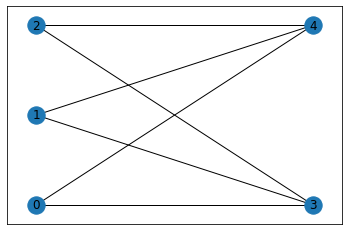

In [19]:
# a)
Ba = nx.Graph()
left, right = [0, 1, 2], [3, 4]
Ba.add_nodes_from(left, bipartite=0)
Ba.add_nodes_from(right, bipartite=1)
Ba.add_edges_from([(i, j) for i in range(3) for j in range(3, 5)])

nx.draw_networkx(Ba, pos = nx.drawing.layout.bipartite_layout(Ba, left))

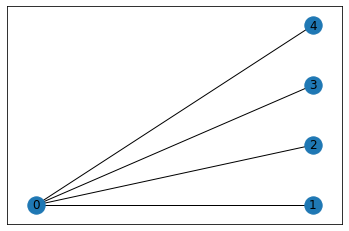

In [20]:
# b)
Bb = nx.Graph()
left, right = [0], [1, 2, 3, 4]
Bb.add_nodes_from(left, bipartite=0)
Bb.add_nodes_from(right, bipartite=1)
Bb.add_edges_from([(0, j) for j in range(1, 5)])

nx.draw_networkx(Bb, pos = nx.drawing.layout.bipartite_layout(Bb, left))

## 3. The Laplacian

Consider the random graphs returned by `nx.fast_gnp_random_graph(n,p)` where $n$ is the number of nodes and $p$ is the probability of an edge between any two nodes. 

Make a list of graphs with $10$ nodes with $p$ ranging from 0 to 1 by steps of 0.01. For each graph, compute the eigenvalues of the Laplacian. Then plot all the eigenvalues for against $p$. For example, above $p=0.01$ you would have a point for each of the 10 real eigenvalues of the graph you made with $p=0.01$. 

What trends do you see in the eigenvalues?

Based on experimentation, what are the eigenvalues of the Laplacian of a completely connected graph?

**Answer:**

a) From the following graph, we can see that as $p$ increases, all of the eigenvalues of the Laplacian matrix increase.

b) the eigenvalues of the Laplacian matrix of a completely connected graph, according to the graph, are all $10$.

In [48]:
space = list(np.linspace(0, 1, 101))
xs = [i * 0.01 for i in range(len(space))]
n = len(space)
eigenvals = []

for p in space:
    Gtmp = nx.fast_gnp_random_graph(10, p)
    lap = nx.laplacian_matrix(Gtmp).toarray()
    eigenvals.append(np.linalg.eigvals(lap))

eigenvals = np.array(eigenvals)

<class 'networkx.utils.decorators.argmap'> compilation 24:4: FutureWarning: laplacian_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.


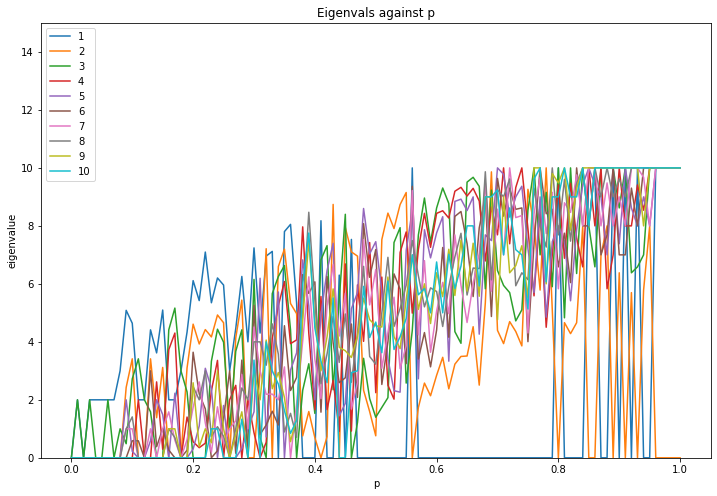

In [50]:
plt.figure(figsize=(12,8))
plt.plot(xs, eigenvals)
plt.title("Eigenvals against p")
plt.xlabel("p")
plt.ylabel("eigenvalue")
plt.ylim([0, 15])
plt.legend(list(range(1, 11)))


## 4. Hamiltonian Circuits

Consider the set of square grid graphs like those returned by the function `nx.grid_graph(dim=[n,n])` where $n>0$. Show that these graphs always have a Hamilton Circuit when $n$ is even. Use networkx to draw the square grid graph for $n=6$, highlighting a Hamilton cycle. 

**Proof:**

For any $n>0$ even, and the corresponding grid graph $G=(V,E)$, we can construct a Hamiltonian Circuit for it:

$V=(i,j),i,j \in \{1,2,3,\cdots,n\}$

Let $F\subset E$, $e=((i,j),(s,t))\in F$ iff 

- ($j=t=1$ or $i=s=1$ or $i=s=n$) or
- ($j=t=2$, $s=i+1$ and $i$ even) or
- ($j=t=n$, $s=i+1$ and $s$ even) or
- ($t=j+1$ and $j\geq 2$)

hence that the given graphs always have a Hamilton Circuit when $n$ is even.

{(0, 0): Text(0, 0, '(0, 0)'),
 (0, 1): Text(1, 0, '(0, 1)'),
 (0, 2): Text(2, 0, '(0, 2)'),
 (0, 3): Text(3, 0, '(0, 3)'),
 (0, 4): Text(4, 0, '(0, 4)'),
 (0, 5): Text(5, 0, '(0, 5)'),
 (1, 0): Text(0, -1, '(1, 0)'),
 (1, 1): Text(1, -1, '(1, 1)'),
 (1, 2): Text(2, -1, '(1, 2)'),
 (1, 3): Text(3, -1, '(1, 3)'),
 (1, 4): Text(4, -1, '(1, 4)'),
 (1, 5): Text(5, -1, '(1, 5)'),
 (2, 0): Text(0, -2, '(2, 0)'),
 (2, 1): Text(1, -2, '(2, 1)'),
 (2, 2): Text(2, -2, '(2, 2)'),
 (2, 3): Text(3, -2, '(2, 3)'),
 (2, 4): Text(4, -2, '(2, 4)'),
 (2, 5): Text(5, -2, '(2, 5)'),
 (3, 0): Text(0, -3, '(3, 0)'),
 (3, 1): Text(1, -3, '(3, 1)'),
 (3, 2): Text(2, -3, '(3, 2)'),
 (3, 3): Text(3, -3, '(3, 3)'),
 (3, 4): Text(4, -3, '(3, 4)'),
 (3, 5): Text(5, -3, '(3, 5)'),
 (4, 0): Text(0, -4, '(4, 0)'),
 (4, 1): Text(1, -4, '(4, 1)'),
 (4, 2): Text(2, -4, '(4, 2)'),
 (4, 3): Text(3, -4, '(4, 3)'),
 (4, 4): Text(4, -4, '(4, 4)'),
 (4, 5): Text(5, -4, '(4, 5)'),
 (5, 0): Text(0, -5, '(5, 0)'),
 (5, 1): Text(

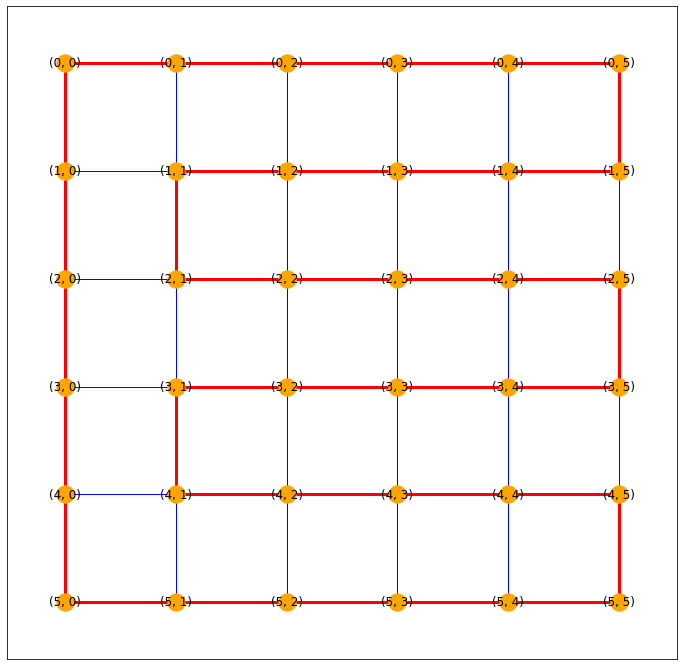

In [97]:
m = 6
Gh = nx.grid_graph(dim=(m, m))

plt.figure(figsize=(12,12))
pos = {(x,y):(y,-x) for x,y in Gh.nodes()}
# nx.draw_networkx(Gh, pos = nx.drawing.layout.kamada_kawai_layout(Gh))

edges = set(Gh.edges())
highlighted_edges = set()
highlighted_edges |= set([((j, i), (j, i + 1)) for i in range(5) for j in range(6)])
highlighted_edges |= set([
    ((0, 0), (1, 0)), ((1, 0), (2, 0)), ((2, 0), (3, 0)), ((3, 0), (4, 0)), ((4, 0), (5, 0)),
    ((0, 5), (1, 5)), ((1, 1), (2, 1)), ((2, 5), (3, 5)), ((3, 1), (4, 1)), ((4, 5), (5, 5)),
])
highlighted_edges -= set([
    ((i, 0), (i, 1)) for i in range(1, 5)
])

nx.draw_networkx_nodes(Gh, pos, nodelist=set(Gh.nodes), node_color='orange')
nx.draw_networkx_edges(Gh, pos, edgelist=highlighted_edges, edge_color='r', width=3.0)
nx.draw_networkx_edges(Gh, pos, edgelist=edges - highlighted_edges, edge_color='b')
nx.draw_networkx_labels(Gh, pos, font_color='black')

# nx.draw(Gh, pos=pos, 
#        node_color='lightgreen', 
#        with_labels=True,
#        node_size=600)

## 5. The Page Rank Algorithm

For the following problem, use the `networkx` `pagerank` function or find the eigenvector of the graph as a Markov Process corresponding to the eigenvector 1. Use undirected graphs.

a) Find a 10 node, connected graph in which all nodes are ranked equally or explain why such a graph does not exist.

b) Find a 10 node, connected graph in which all nodes are ranked differently or explain why such a graph does not exist.

c) Find a 10 node, connected graph in which there are two sets $A$ and $B$ of $5$ nodes for which all nodes in $A$ are ranked the same and all nodes in $B$ are ranked the same, but different from nodes in $A$. Or explain why such a graph does not exist.

$MR=R$, $(M-I)R=\mathbb{0}$, $M\in\mathbb{R}^{10\times 10}, R\in\mathbb{R}^{1\times 10}$

a) if $R = \dfrac{1}{10}\mathbb{1}$, we can let every element in the matrix $M$ except the diagonal elements be $\dfrac{1}{9}$, hence such graph exists, and it is a complete graph with uniform edge weights.

b) Such graph doesn't exist.

c) Such graph doesn't exist.

In [114]:
space = list(np.linspace(0, 1, 1001))
xs = [i * 0.001 for i in range(len(space))]
n = len(space)
eigenvals = []

for p in space:
    Gtmp = nx.fast_gnp_random_graph(10, p)
    pr = np.floor(np.array(list(nx.pagerank_numpy(Gtmp, 0.5).values())) * 1000)
    print(pr)

[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[166.  83.  83.  83.  83.  83.  83.  83.  83. 166.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[ 83. 166.  83.  83.  83.  83.  83.  83. 166.  83.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[ 83.  83. 166.  83.  83.  83.  83. 166.  83.  83.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[100.  99. 100. 100. 100. 100. 100. 100. 100. 100.]
[ 71.  71. 1

C:\Users\35995\AppData\Local\Temp\ipykernel_23792\2323104754.py:8: DeprecationWarning: networkx.pagerank_numpy is deprecated and will be removed in NetworkX 3.0, use networkx.pagerank instead.
  pr = np.floor(np.array(list(nx.pagerank_numpy(Gtmp, 0.5).values())) * 1000)
